# Part 4 – Data Preprocessing and GRU Preparation
**PM2.5 Forecasting using GRU** | Master 1 mini-project | Person 4

Input: `combined_gee_pm25_clean.csv` (output of Part 1, 40,983 rows).

**Forecasting scenario:** predict PM2.5 of day *t* from the **previous 7 days** (day *t-1* is always observed). Nothing from day *t* (except the calendar position of the target day) is used as input, so the model is a genuine 1-day-ahead forecaster.

**Leakage rules applied (protocol §5.3):** final test period isolated first, stations selected on development data only, lags never built across gaps, imputers/scalers fitted on each training fold only.

## 1. Configuration and loading

In [1]:
import os, json, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import GroupKFold, KFold
warnings.filterwarnings("ignore")

SEED = 42
np.random.seed(SEED)

WINDOW = 7                  # days of history given to the GRU
MIN_OBS_IN_WINDOW = 3       # at least 3 observed days among the 7 (t-1 must be one of them)
MIN_STATION_OBS = 150       # minimum observations per station in the development period
TEST_START = pd.Timestamp("2025-01-01")   # final future test period (never used in any fold)
OUT_DIR = "results/04"
os.makedirs(OUT_DIR, exist_ok=True)

CANDIDATES = [
    "Files/combined_gee_pm25_clean.csv",
    "/content/combined_gee_pm25_clean.csv",
    "/content/PM25-Forecasting-GRU/Files/combined_gee_pm25_clean.csv",
    "/mnt/user-data/uploads/combined_gee_pm25_clean.csv",
]
DATA_PATH = next(p for p in CANDIDATES if os.path.exists(p))
print("Reading:", DATA_PATH)

df = (pd.read_csv(DATA_PATH, parse_dates=["date"])
        .sort_values(["id", "date"]).reset_index(drop=True))

# sanity checks on the Part 1 output
assert df.duplicated(["id", "date"]).sum() == 0
assert df["pm25"].gt(0).all() and df["pm25"].lt(500).all()
print("Shape:", df.shape, "| stations:", df["id"].nunique())
print("Dates:", df["date"].min().date(), "->", df["date"].max().date())

Reading: /mnt/user-data/uploads/combined_gee_pm25_clean.csv


Shape: (40983, 15) | stations: 95
Dates: 2016-11-25 -> 2026-04-06


## 2. Final test period (isolated first)
Everything from **2025-01-01** onward is the future test set. All statistics used for decisions below (missingness, station selection, outliers, folds) come from the development period only.

In [2]:
dev_df  = df[df["date"] <  TEST_START].copy()
test_df = df[df["date"] >= TEST_START].copy()
print(f"Development rows: {len(dev_df):,}  ({dev_df['date'].min().date()} -> {dev_df['date'].max().date()})")
print(f"Test rows       : {len(test_df):,}  ({test_df['date'].min().date()} -> {test_df['date'].max().date()})")

Development rows: 31,286  (2016-11-25 -> 2024-12-31)
Test rows       : 9,697  (2025-01-01 -> 2026-04-06)


## 3. Missingness analysis (by variable, month and station)
Sentinel-5P variables (NO2, CO, O3) are the only ones with missing values. Protocol §5.3.1: **training-fold median imputation + one missingness indicator per column, no forward-fill.**

In [3]:
gas = ["NO2", "CO", "O3"]
all_vars = ["temperature_celsius", "pressure_mb", "wind_u", "wind_v", "AOD"] + gas
miss_var = dev_df[all_vars].isna().mean().mul(100).round(2).rename("pct_missing")
print(miss_var.to_string())

# by year-month
tmp = dev_df.assign(year_month=dev_df["date"].dt.to_period("M").astype(str))
miss_month = tmp.groupby("year_month")[gas].agg(lambda s: s.isna().mean() * 100).round(2)
miss_month["n_obs"] = tmp.groupby("year_month").size()
miss_month.to_csv(f"{OUT_DIR}/missingness_by_month.csv")

# by station
miss_station = (dev_df.groupby(["id", "sensor_name"])[gas]
                .agg(lambda s: s.isna().mean() * 100).round(2))
miss_station["n_obs"] = dev_df.groupby(["id", "sensor_name"]).size()
miss_station = miss_station.sort_values("NO2", ascending=False)
miss_station.to_csv(f"{OUT_DIR}/missingness_by_station.csv")

print("\nMonths with >50% missing NO2:", int((miss_month["NO2"] > 50).sum()), "of", len(miss_month))
print("Stations with >50% missing NO2:", int((miss_station["NO2"] > 50).sum()), "of", len(miss_station))
print("\nWorst 8 stations (NO2 % missing):")
print(miss_station.head(8).to_string())

temperature_celsius    0.00
pressure_mb            0.00
wind_u                 0.00
wind_v                 0.00
AOD                    0.00
NO2                    7.69
CO                     7.69
O3                     7.82

Months with >50% missing NO2: 18 of 88
Stations with >50% missing NO2: 1 of 74

Worst 8 stations (NO2 % missing):
                              NO2     CO     O3  n_obs
id sensor_name                                        
72 FR03030                  55.48  55.48  56.18    283
70 FR03006                  47.31  47.31  47.69    260
71 FR03043                  46.47  46.47  47.21    269
69 FR03029                  45.85  45.85  46.64    253
7  VALÈNCIA - MOLÍ DEL SOL  30.72  30.72  30.72    319
12 QUART DE POBLET          21.48  21.48  21.90    717
6  VALÈNCIA-PISTA DE SILLA  21.48  21.48  21.90    717
36 ALMASSORA-C. P. OCHANDO  21.11  21.11  21.38    739


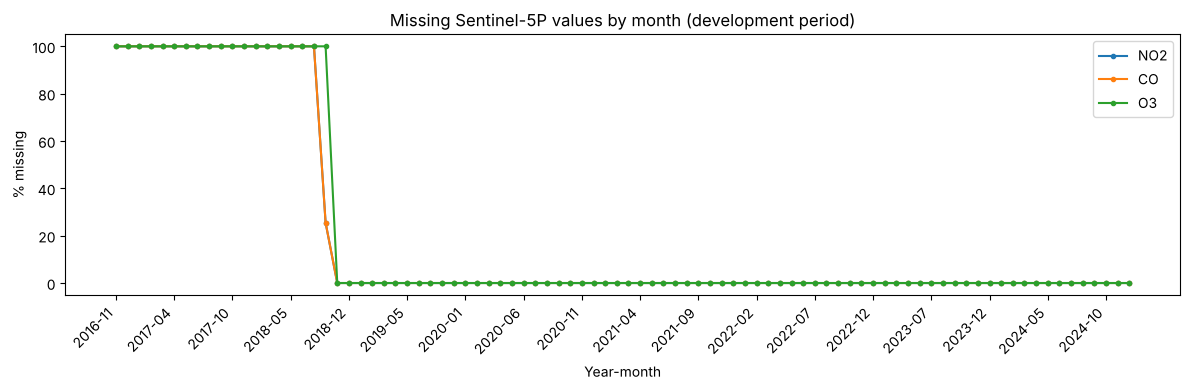

In [4]:
fig, ax = plt.subplots(figsize=(12, 4))
for g in gas:
    ax.plot(miss_month.index, miss_month[g], marker="o", ms=3, label=g)
ax.set_title("Missing Sentinel-5P values by month (development period)")
ax.set_ylabel("% missing"); ax.set_xlabel("Year-month")
step = max(1, len(miss_month) // 15)
ax.set_xticks(range(0, len(miss_month), step))
ax.set_xticklabels(miss_month.index[::step], rotation=45, ha="right")
ax.legend(); plt.tight_layout()
plt.savefig(f"{OUT_DIR}/missingness_by_month.png", dpi=150); plt.show()

## 4. Station selection (decided on development data only)
Stations with too few observations cannot provide enough history for a 7-day window and would add noise to spatial folds.

In [5]:
cnt = dev_df.groupby("id").size()
keep_ids = cnt[cnt >= MIN_STATION_OBS].index
st = (dev_df.groupby(["id", "sensor_name", "latitude", "longitude"])
      .agg(n_obs_dev=("pm25", "size"), first=("date", "min"), last=("date", "max")).reset_index())
st["kept"] = st["id"].isin(keep_ids)
st.to_csv(f"{OUT_DIR}/stations_selection.csv", index=False)

print(f"Stations in dev data : {cnt.size}")
print(f"Kept (>= {MIN_STATION_OBS} obs) : {len(keep_ids)}")
print(f"Dropped              : {cnt.size - len(keep_ids)}")
print(f"Test-only stations (absent from dev) are dropped automatically: "
      f"{test_df.loc[~test_df['id'].isin(cnt.index), 'id'].nunique()}")

dfk = df[df["id"].isin(keep_ids)].copy()
print(f"Rows kept: {len(dfk):,} of {len(df):,}")

Stations in dev data : 74
Kept (>= 150 obs) : 61
Dropped              : 13
Test-only stations (absent from dev) are dropped automatically: 21
Rows kept: 35,598 of 40,983


## 5. Outlier treatment
PM2.5 is strongly right-skewed. Extreme values above the IQR fence are **genuine pollution episodes** (e.g. dust intrusions in the Mediterranean) and the invalid sentinels (≤0, ≥500) were already removed in Part 1. **Decision: no target removal or clipping.** An optional feature clipping (percentiles learned on the training fold) is available in `FoldPreprocessor` so Part 5 can compare MAE/RMSE/R² with and without it on the same held-out data.

In [6]:
y = dev_df["pm25"]
q1, q3 = y.quantile([0.25, 0.75]); iqr = q3 - q1
fence = q3 + 1.5 * iqr
summary = {
    "n_dev": len(y), "mean": y.mean(), "median": y.median(), "std": y.std(),
    "skewness": y.skew(), "kurtosis": y.kurt(),
    "q1": q1, "q3": q3, "iqr_upper_fence": fence,
    "n_above_fence": int((y > fence).sum()), "pct_above_fence": (y > fence).mean() * 100,
    "pct_above_25": (y > 25).mean() * 100, "pct_above_50": (y > 50).mean() * 100,
    "max": y.max(),
}
outlier_summary = pd.Series(summary).round(3)
outlier_summary.to_csv(f"{OUT_DIR}/outlier_summary.csv", header=["value"])
print(outlier_summary.to_string())

n_dev              31286.000
mean                   9.317
median                 7.733
std                   10.344
skewness              19.113
kurtosis             666.646
q1                     4.542
q3                    12.000
iqr_upper_fence       23.188
n_above_fence       1117.000
pct_above_fence        3.570
pct_above_25           2.704
pct_above_50           0.291
max                  484.982


## 6. Daily time series per station and feature construction
Each kept station gets a **regular daily timeline** (first to last date). Days without an observation stay `NaN` and are flagged by an `obs` channel; they are **never interpolated or forward-filled**, and no lag is computed across a gap.

Per-timestep features (14): temperature, pressure, wind_u, wind_v, wind speed, NO2, CO, O3, AOD, **past PM2.5**, `miss_NO2`, `miss_CO`, `miss_O3`, `obs`. Station `id`, latitude and longitude are **not** features (kept in `meta.csv` only).
Static features (2): sin/cos of day-of-year of the **target** day.

Rolling statistics and differences are not hand-built here: the GRU receives the raw 7-day sequence and learns them itself. (Tabular models in other parts can derive them from the same windows.)

In [7]:
CONT  = ["temperature_celsius", "pressure_mb", "wind_u", "wind_v", "wind_speed",
         "NO2", "CO", "O3", "AOD", "pm25_lag"]
FLAGS = ["miss_NO2", "miss_CO", "miss_O3", "obs"]
FEATURES = CONT + FLAGS
STATIC = ["doy_sin_target", "doy_cos_target"]
IDX = {n: i for i, n in enumerate(FEATURES)}

X_list, S_list, y_list, meta_rows = [], [], [], []

for sid, g in dfk.groupby("id"):
    info = g.iloc[0]
    g = g.set_index("date").sort_index()
    grid = pd.date_range(g.index.min(), g.index.max(), freq="D")
    gg = g.reindex(grid)                       # regular daily timeline, NaN on missing days
    obs = gg["pm25"].notna().to_numpy()

    F = np.full((len(grid), len(FEATURES)), np.nan, dtype=np.float32)
    F[:, IDX["temperature_celsius"]] = gg["temperature_celsius"]
    F[:, IDX["pressure_mb"]] = gg["pressure_mb"]
    F[:, IDX["wind_u"]] = gg["wind_u"]
    F[:, IDX["wind_v"]] = gg["wind_v"]
    F[:, IDX["wind_speed"]] = np.hypot(gg["wind_u"], gg["wind_v"])
    for c in gas:
        F[:, IDX[c]] = gg[c]
        F[:, IDX["miss_" + c]] = gg[c].isna().astype(np.float32)
    F[:, IDX["AOD"]] = gg["AOD"]
    F[:, IDX["pm25_lag"]] = gg["pm25"]         # past PM2.5 (only ever read for days < target)
    F[:, IDX["obs"]] = obs.astype(np.float32)

    for i in range(WINDOW, len(grid)):
        if not (obs[i] and obs[i - 1]):        # target observed and yesterday observed
            continue
        n_obs = int(obs[i - WINDOW:i].sum())
        if n_obs < MIN_OBS_IN_WINDOW:
            continue
        doy = grid[i].dayofyear
        X_list.append(F[i - WINDOW:i])         # days t-7 ... t-1 only
        S_list.append([np.sin(2 * np.pi * doy / 365.25), np.cos(2 * np.pi * doy / 365.25)])
        y_list.append(gg["pm25"].iloc[i])
        meta_rows.append((sid, info["sensor_name"], info["latitude"], info["longitude"],
                          grid[i], n_obs))

X = np.stack(X_list).astype(np.float32)        # (n_samples, 7, 14), NaN kept (imputed per fold later)
S = np.array(S_list, dtype=np.float32)         # (n_samples, 2)
y_arr = np.array(y_list, dtype=np.float32)
meta = pd.DataFrame(meta_rows, columns=["id", "sensor_name", "latitude", "longitude",
                                        "target_date", "n_obs_window"])
meta.insert(0, "sample_id", np.arange(len(meta)))
meta["y"] = y_arr
meta["split"] = np.where(meta["target_date"] >= TEST_START, "test", "dev")

print("X:", X.shape, "| S:", S.shape, "| y:", y_arr.shape)
print(meta["split"].value_counts().to_string())
print(f"\nSamples kept: {len(meta):,} of {len(dfk):,} observed rows")
print("Observed days in window (n_obs_window):")
print(meta["n_obs_window"].value_counts().sort_index().to_string())

X: (21248, 7, 14) | S: (21248, 2) | y: (21248,)
split
dev     17891
test     3357

Samples kept: 21,248 of 35,598 observed rows
Observed days in window (n_obs_window):
n_obs_window
3    2840
4    4011
5    5181
6    5070
7    4146


### 6.1 Leakage sanity checks on the windows

In [8]:
lookup = df.set_index(["id", "date"])["pm25"]
rng = np.random.default_rng(SEED)
pick = rng.choice(len(meta), size=1000, replace=False)
ok_prev, ok_obs = 0, 0
for j in pick:
    r = meta.iloc[j]
    prev_val = lookup.get((r["id"], r["target_date"] - pd.Timedelta(days=1)), np.nan)
    ok_prev += bool(np.isclose(X[j, -1, IDX["pm25_lag"]], prev_val))   # last step = day t-1
    ok_obs  += bool(X[j, -1, IDX["obs"]] == 1)
assert ok_prev == len(pick) and ok_obs == len(pick)
assert not np.isclose(X[pick, -1, IDX["pm25_lag"]], y_arr[pick]).all()  # window does not contain the target
print(f"{len(pick)}/{len(pick)} windows end exactly at t-1 with the real PM2.5 of that day.")

# missingness left in the raw array (imputed later, per fold)
nan_share = pd.Series(np.isnan(X).reshape(-1, X.shape[2]).mean(0) * 100, index=FEATURES).round(2)
print("\n% NaN per feature in raw windows (unobserved days + missing S5P):")
print(nan_share.to_string())

1000/1000 windows end exactly at t-1 with the real PM2.5 of that day.

% NaN per feature in raw windows (unobserved days + missing S5P):
temperature_celsius    26.10
pressure_mb            26.10
wind_u                 26.10
wind_v                 26.10
wind_speed             26.10
NO2                    31.08
CO                     31.08
O3                     31.08
AOD                    26.10
pm25_lag               26.10
miss_NO2                0.00
miss_CO                 0.00
miss_O3                 0.00
obs                     0.00


## 7. Validation folds (saved once, reused by all models)
Folds are built on the **development samples only** (the 2025+ test samples never appear). Fold values are `sample_id`s (row index in `X_raw.npy`).

| Scheme | File | Purpose |
|---|---|---|
| Temporal, 5 folds, expanding window, 1-day gap | `folds_temporal.json` | Mandatory, model selection |
| Spatial `GroupKFold` by station id | `folds_spatial.json` | Unseen locations |
| Shuffled `KFold`, seed 42 | `folds_standard.json` | Diagnostic only (optimistic) |

In [9]:
dev = meta[meta["split"] == "dev"].sort_values(["target_date", "id"]).reset_index(drop=True)
n = len(dev)
dates = dev["target_date"].to_numpy()

# ---- Temporal: 6 date-aligned chunks by row count; fold k trains on chunks 0..k, validates on chunk k+1
edges = [dev["target_date"].min()] + [pd.Timestamp(dates[int(n * k / 6)]) for k in range(1, 6)] \
        + [dev["target_date"].max() + pd.Timedelta(days=1)]
GAP_DAYS = 1
folds_temporal = []
for k in range(5):
    val_start, val_end = edges[k + 1], edges[k + 2]
    tr = dev[dev["target_date"] < val_start - pd.Timedelta(days=GAP_DAYS)]   # 1 day removed before validation
    va = dev[(dev["target_date"] >= val_start) & (dev["target_date"] < val_end)]
    folds_temporal.append({"fold": k, "train": tr["sample_id"].tolist(), "val": va["sample_id"].tolist(),
                           "train_end": str(tr["target_date"].max().date()),
                           "val_start": str(va["target_date"].min().date()),
                           "val_end": str(va["target_date"].max().date())})

# ---- Spatial: GroupKFold by station id (id is a group only, never a feature)
folds_spatial = []
for k, (tr, va) in enumerate(GroupKFold(n_splits=5).split(dev, groups=dev["id"])):
    folds_spatial.append({"fold": k, "train": dev.iloc[tr]["sample_id"].tolist(),
                          "val": dev.iloc[va]["sample_id"].tolist(),
                          "val_stations": sorted(dev.iloc[va]["id"].unique().tolist())})

# ---- Standard random KFold (diagnostic only)
folds_standard = []
for k, (tr, va) in enumerate(KFold(n_splits=5, shuffle=True, random_state=SEED).split(dev)):
    folds_standard.append({"fold": k, "train": dev.iloc[tr]["sample_id"].tolist(),
                           "val": dev.iloc[va]["sample_id"].tolist()})

schemes = {"temporal": folds_temporal, "spatial": folds_spatial, "standard": folds_standard}
for name, folds in schemes.items():
    with open(f"{OUT_DIR}/folds_{name}.json", "w") as f:
        json.dump({"scheme": name, "n_splits": 5, "seed": SEED, "folds": folds}, f)

test_idx = meta.loc[meta["split"] == "test", "sample_id"].tolist()
with open(f"{OUT_DIR}/test_idx.json", "w") as f:
    json.dump({"test_start": str(TEST_START.date()), "idx": test_idx}, f)

for name, folds in schemes.items():
    print(name, [(len(f["train"]), len(f["val"])) for f in folds])
for f in folds_temporal:
    print(f"temporal fold {f['fold']}: train up to {f['train_end']} | val {f['val_start']} -> {f['val_end']}")

temporal [(2964, 2983), (5959, 2966), (8919, 2997), (11921, 2952), (14844, 3015)]
spatial [(14333, 3558), (14330, 3561), (14321, 3570), (14257, 3634), (14323, 3568)]
standard [(14312, 3579), (14313, 3578), (14313, 3578), (14313, 3578), (14313, 3578)]
temporal fold 0: train up to 2020-06-13 | val 2020-06-15 -> 2021-10-15
temporal fold 1: train up to 2021-10-14 | val 2021-10-16 -> 2022-09-27
temporal fold 2: train up to 2022-09-26 | val 2022-09-28 -> 2023-11-03
temporal fold 3: train up to 2023-11-02 | val 2023-11-04 -> 2024-07-01
temporal fold 4: train up to 2024-06-30 | val 2024-07-02 -> 2024-12-31


### 7.1 Leakage checks on the folds

In [10]:
checks = []
test_set = set(test_idx)
dd = meta.set_index("sample_id")
for name, folds in schemes.items():
    for f in folds:
        tr, va = set(f["train"]), set(f["val"])
        c = {"scheme": name, "fold": f["fold"],
             "no_train_val_overlap": tr.isdisjoint(va),
             "no_test_in_fold": tr.isdisjoint(test_set) and va.isdisjoint(test_set)}
        if name == "temporal":
            gap = (dd.loc[list(va), "target_date"].min() - dd.loc[list(tr), "target_date"].max()).days
            c["temporal_gap_days"] = gap
            c["train_strictly_before_val"] = gap >= 2     # >= 1 full day between last train and first val
        if name == "spatial":
            c["no_station_overlap"] = set(dd.loc[list(tr), "id"]).isdisjoint(set(dd.loc[list(va), "id"]))
        checks.append(c)
leak = pd.DataFrame(checks)
leak.to_csv(f"{OUT_DIR}/leakage_checks.csv", index=False)
print(leak.to_string(index=False))
bool_cols = [c for c in leak.columns if leak[c].dtype == bool]
assert leak[bool_cols].all().all(), "A leakage check failed"
print("\nAll leakage checks passed.")

  scheme  fold  no_train_val_overlap  no_test_in_fold  temporal_gap_days train_strictly_before_val no_station_overlap
temporal     0                  True             True                2.0                      True                NaN
temporal     1                  True             True                2.0                      True                NaN
temporal     2                  True             True                2.0                      True                NaN
temporal     3                  True             True                2.0                      True                NaN
temporal     4                  True             True                2.0                      True                NaN
 spatial     0                  True             True                NaN                       NaN               True
 spatial     1                  True             True                NaN                       NaN               True
 spatial     2                  True             True   

## 8. Fold-safe preprocessing for the GRU
`FoldPreprocessor` (saved in `gru_preprocessing.py`) is **fitted on the training windows of one fold only**:
1. median imputation of NaN values (NO2/CO/O3 among observed days), medians learned on the training fold;
2. optional percentile clipping of features (learned on training fold, off by default);
3. `StandardScaler` on the 10 continuous features (observed timesteps only);
4. unobserved days are set to 0 after scaling (the `obs` channel tells the GRU they are padding);
5. missingness indicators, `obs` and sin/cos are left unscaled.

In [11]:
%%writefile gru_preprocessing.py
# Fold-safe preprocessing for the GRU (Part 4). Fit on the training fold only.
import json
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler

N_CONT = 10        # first 10 features are continuous (see feature_names.json)
OBS_IDX = 13       # index of the 'obs' channel


class FoldPreprocessor:
    def __init__(self, n_cont=N_CONT, obs_idx=OBS_IDX, clip_q=None):
        self.n_cont = n_cont
        self.obs_idx = obs_idx
        self.clip_q = clip_q          # e.g. 0.005 -> clip features to [0.5%, 99.5%] learned on train

    def fit(self, X, train_idx):
        Xt = X[np.asarray(train_idx)]
        obs = Xt[:, :, self.obs_idx] == 1
        C = Xt[:, :, :self.n_cont][obs]                 # observed timesteps only
        self.median_ = np.nanmedian(C, axis=0)
        C = np.where(np.isnan(C), self.median_, C)
        if self.clip_q:
            self.lo_, self.hi_ = np.quantile(C, [self.clip_q, 1 - self.clip_q], axis=0)
            C = np.clip(C, self.lo_, self.hi_)
        self.scaler_ = StandardScaler().fit(C)
        return self

    def transform(self, X, S, idx):
        idx = np.asarray(idx)
        Xi = X[idx].copy()
        obs = Xi[:, :, self.obs_idx] == 1
        C = Xi[:, :, :self.n_cont]
        C = np.where(np.isnan(C), self.median_, C)      # median from TRAIN fold
        if self.clip_q:
            C = np.clip(C, self.lo_, self.hi_)
        C = (C - self.scaler_.mean_) / self.scaler_.scale_
        C[~obs] = 0.0                                   # padding for unobserved days
        Xi[:, :, :self.n_cont] = C
        return Xi.astype(np.float32), S[idx].astype(np.float32)


def load_part4(out_dir="results/04"):
    # Load everything produced by the Part 4 notebook.
    X = np.load(f"{out_dir}/X_raw.npy")
    S = np.load(f"{out_dir}/X_static.npy")
    y = np.load(f"{out_dir}/y.npy")
    meta = pd.read_csv(f"{out_dir}/meta.csv", parse_dates=["target_date"])
    folds = {k: json.load(open(f"{out_dir}/folds_{k}.json"))["folds"]
             for k in ["temporal", "spatial", "standard"]}
    test_idx = json.load(open(f"{out_dir}/test_idx.json"))["idx"]
    return X, S, y, meta, folds, test_idx

Writing gru_preprocessing.py


In [12]:
import importlib, gru_preprocessing
importlib.reload(gru_preprocessing)
from gru_preprocessing import FoldPreprocessor

rows = []
for name, folds in schemes.items():
    for f in folds:
        pre = FoldPreprocessor().fit(X, f["train"])
        Xtr, Str = pre.transform(X, S, f["train"])
        Xva, Sva = pre.transform(X, S, f["val"])

        # the transformed arrays contain no NaN
        assert not np.isnan(Xtr).any() and not np.isnan(Xva).any()

        # statistics come from the TRAIN fold only: recompute them independently and compare
        tr_idx = np.array(f["train"])
        obs_tr = X[tr_idx][:, :, IDX["obs"]] == 1
        train_mean_lag = np.nanmean(X[tr_idx][:, :, IDX["pm25_lag"]][obs_tr])
        assert np.isclose(pre.scaler_.mean_[IDX["pm25_lag"]], train_mean_lag, rtol=1e-4)

        # on observed steps the TRAIN set is centered (~0); the validation set is not forced to be
        obs_va = X[np.array(f["val"])][:, :, IDX["obs"]] == 1
        rows.append({
            "scheme": name, "fold": f["fold"],
            "n_train": len(f["train"]), "n_val": len(f["val"]),
            "train_pm25_mean": float(y_arr[tr_idx].mean()),
            "val_pm25_mean": float(y_arr[np.array(f["val"])].mean()),
            "scaler_mean_pm25_lag(train)": float(pre.scaler_.mean_[IDX["pm25_lag"]]),
            "train_scaled_mean": float(Xtr[:, :, IDX["pm25_lag"]][obs_tr].mean()),
            "val_scaled_mean": float(Xva[:, :, IDX["pm25_lag"]][obs_va].mean()),
        })
fold_summary = pd.DataFrame(rows).round(3)
fold_summary.to_csv(f"{OUT_DIR}/fold_preprocessing_summary.csv", index=False)
print(fold_summary.to_string(index=False))
print("\nFitted on train only: train scaled mean ~ 0, validation scaled mean differs (no information leaked).")

  scheme  fold  n_train  n_val  train_pm25_mean  val_pm25_mean  scaler_mean_pm25_lag(train)  train_scaled_mean  val_scaled_mean
temporal     0     2964   2983            9.877          7.681                        9.618               -0.0           -0.321
temporal     1     5959   2966            8.765         10.423                        8.390                0.0            0.317
temporal     2     8919   2997            9.321          9.881                        9.189                0.0            0.032
temporal     3    11921   2952            9.459          8.887                        9.305                0.0           -0.071
temporal     4    14844   3015            9.348         10.186                        9.132                0.0            0.066
 spatial     0    14333   3558            9.654          8.812                        9.431                0.0           -0.084
 spatial     1    14330   3561            9.460          9.593                        9.265             

## 9. Figures

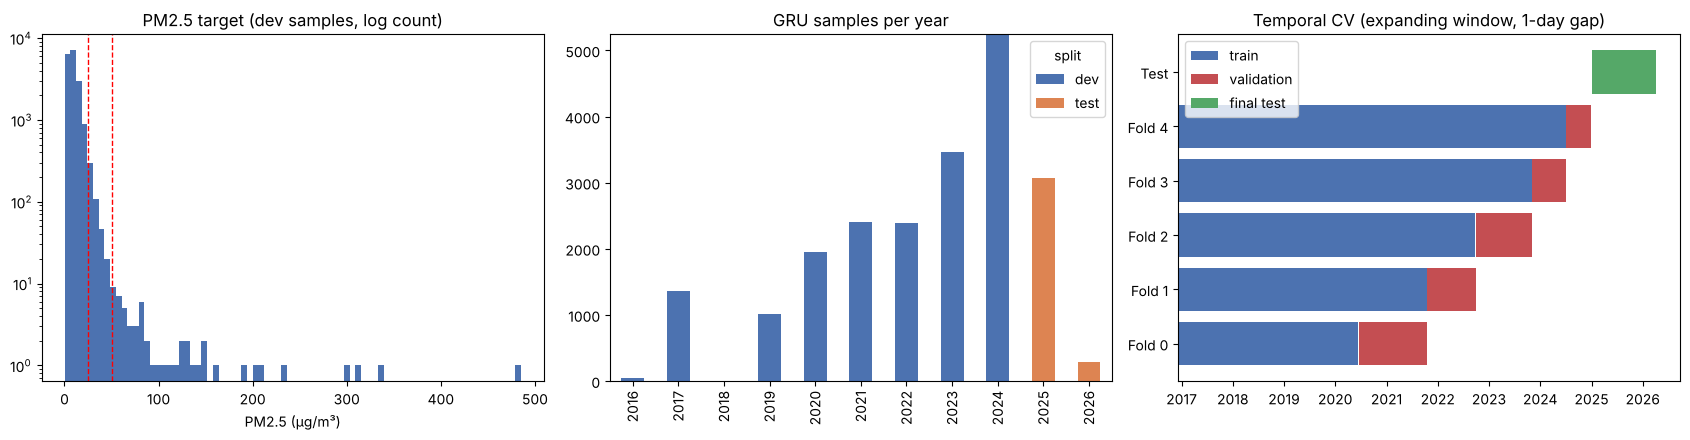

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))

# (a) PM2.5 distribution
ax = axes[0]
ax.hist(meta.loc[meta.split == "dev", "y"], bins=80, color="#4C72B0")
for t in (25, 50):
    ax.axvline(t, color="red", ls="--", lw=1)
ax.set_yscale("log"); ax.set_title("PM2.5 target (dev samples, log count)")
ax.set_xlabel("PM2.5 (µg/m³)")

# (b) samples per year by split
ax = axes[1]
yy = meta.assign(year=meta["target_date"].dt.year).groupby(["year", "split"]).size().unstack(fill_value=0)
yy.plot(kind="bar", stacked=True, ax=ax, color=["#4C72B0", "#DD8452"])
ax.set_title("GRU samples per year"); ax.set_xlabel("")

# (c) temporal folds
ax = axes[2]
for f in folds_temporal:
    k = f["fold"]
    tr_d = dd.loc[f["train"], "target_date"]; va_d = dd.loc[f["val"], "target_date"]
    ax.barh(k, (tr_d.max() - tr_d.min()).days, left=tr_d.min(), color="#4C72B0", label="train" if k == 0 else None)
    ax.barh(k, (va_d.max() - va_d.min()).days, left=va_d.min(), color="#C44E52", label="validation" if k == 0 else None)
ax.barh(5, (meta.target_date.max() - TEST_START).days, left=TEST_START, color="#55A868", label="final test")
ax.set_yticks(range(6)); ax.set_yticklabels([f"Fold {i}" for i in range(5)] + ["Test"])
ax.set_title("Temporal CV (expanding window, 1-day gap)"); ax.legend(loc="upper left")
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/part4_overview.png", dpi=150); plt.show()

## 10. Save outputs for Part 5 (GRU training)

In [14]:
np.save(f"{OUT_DIR}/X_raw.npy", X)            # (n, 7, 14) raw windows, NaN kept (impute per fold)
np.save(f"{OUT_DIR}/X_static.npy", S)         # (n, 2)
np.save(f"{OUT_DIR}/y.npy", y_arr)            # (n,) PM2.5 in µg/m³ (original scale)
meta.to_csv(f"{OUT_DIR}/meta.csv", index=False)

with open(f"{OUT_DIR}/feature_names.json", "w") as f:
    json.dump({"sequence_features": FEATURES, "static_features": STATIC, "window": WINDOW,
               "continuous_idx": list(range(len(CONT))), "obs_idx": IDX["obs"]}, f, indent=2)

config = {"seed": SEED, "window_days": WINDOW, "min_obs_in_window": MIN_OBS_IN_WINDOW,
          "min_station_obs": MIN_STATION_OBS, "test_start": str(TEST_START.date()),
          "forecast_horizon_days": 1, "temporal_gap_days": GAP_DAYS,
          "n_samples": int(len(meta)), "n_dev": int((meta.split == "dev").sum()),
          "n_test": int((meta.split == "test").sum()), "n_stations": int(meta["id"].nunique()),
          "input_file": os.path.basename(DATA_PATH)}
with open(f"{OUT_DIR}/config.json", "w") as f:
    json.dump(config, f, indent=2)

print(json.dumps(config, indent=2))
print("\nFiles:", sorted(os.listdir(OUT_DIR)))

{
  "seed": 42,
  "window_days": 7,
  "min_obs_in_window": 3,
  "min_station_obs": 150,
  "test_start": "2025-01-01",
  "forecast_horizon_days": 1,
  "temporal_gap_days": 1,
  "n_samples": 21248,
  "n_dev": 17891,
  "n_test": 3357,
  "n_stations": 61,
  "input_file": "combined_gee_pm25_clean.csv"
}

Files: ['X_raw.npy', 'X_static.npy', 'config.json', 'feature_names.json', 'fold_preprocessing_summary.csv', 'folds_spatial.json', 'folds_standard.json', 'folds_temporal.json', 'leakage_checks.csv', 'meta.csv', 'missingness_by_month.csv', 'missingness_by_month.png', 'missingness_by_station.csv', 'outlier_summary.csv', 'part4_overview.png', 'stations_selection.csv', 'test_idx.json', 'y.npy']


## 11. Summary (for the report and slide 7)
- **Missing values:** only NO2/CO/O3 (≈6%); training-fold median imputation + missingness indicators, no forward/backward fill.
- **Outliers:** extreme PM2.5 kept (genuine episodes); invalid sentinels removed in Part 1; optional train-fold feature clipping available.
- **Daily series:** regular daily timeline per station; gaps stay `NaN` and are flagged, never interpolated; lags never cross gaps.
- **Stations:** kept only stations with ≥150 development observations (decided before splitting).
- **GRU input:** `(samples, 7, 14)` windows ending at *t-1*, plus 2 static calendar features; forecast horizon = 1 day.
- **No leakage:** 2025+ test isolated first; folds saved once; imputer and scaler fitted per training fold; automated checks in `leakage_checks.csv`.

**How Part 5 loads everything**
```python
from gru_preprocessing import FoldPreprocessor, load_part4
X, S, y, meta, folds, test_idx = load_part4("results/04")
for f in folds["temporal"]:
    pre = FoldPreprocessor().fit(X, f["train"])
    Xtr, Str = pre.transform(X, S, f["train"]); ytr = y[f["train"]]
    Xva, Sva = pre.transform(X, S, f["val"]);   yva = y[f["val"]]
```